In [24]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor
from xgboost import plot_importance


In [25]:
def lease_to_years(value):
    if pd.isna(value):
        return np.nan
    
    years = re.search(r"(\d+)\s*years?", str(value))
    months = re.search(r"(\d+)\s*months?", str(value))
    return (int(years.group(1)) if years else 0) + (int(months.group(1)) / 12 if months else 0)

In [26]:
num_cols = ['floor_area_sqm', 'lease_commence_date', 'sale_year', 'sale_month', 'remaining_lease_years']
cat_cols = ['town', 'flat_type', 'street_name', 'storey_range', 'flat_model']

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
])

cat_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('cat', cat_pipeline, cat_cols),
    ('num', num_pipeline, num_cols)
])

df = pd.read_csv("/Users/amel/Projects/HDBPredictor/data.csv")
df["sale_date"] = pd.to_datetime(df["month"], format="%Y-%m")

df["remaining_lease_years"] = df["remaining_lease"].apply(lease_to_years)

df["sale_year"] = df["sale_date"].dt.year
df["sale_month"] = df["sale_date"].dt.month

X = df.drop(columns=["resale_price", "block", "month", "sale_date", "remaining_lease"])
y = df["resale_price"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error


model = XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",
    max_depth=5,
    learning_rate=0.05,
    n_estimators=1000,
    reg_alpha=0,
    random_state=42,
    n_jobs=-1
)


pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model)
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print(f"MAE: ${mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: ${root_mean_squared_error(y_test, y_pred):.2f}")
print(f"R^2: {r2_score(y_test, y_pred):.3f}")

MAE: $26818.10
RMSE: $36560.81
R^2: 0.964


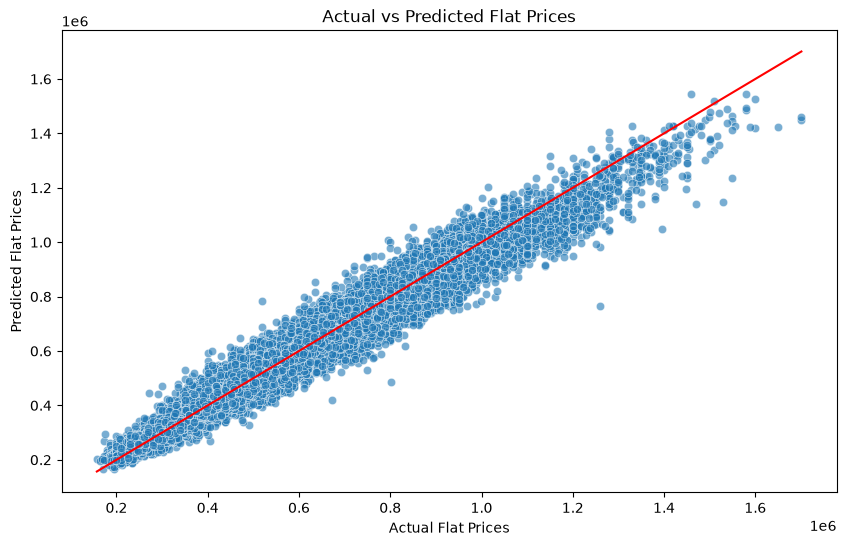

In [28]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted Flat Prices')
plt.xlabel('Actual Flat Prices')
plt.ylabel('Predicted Flat Prices')
plt.show()

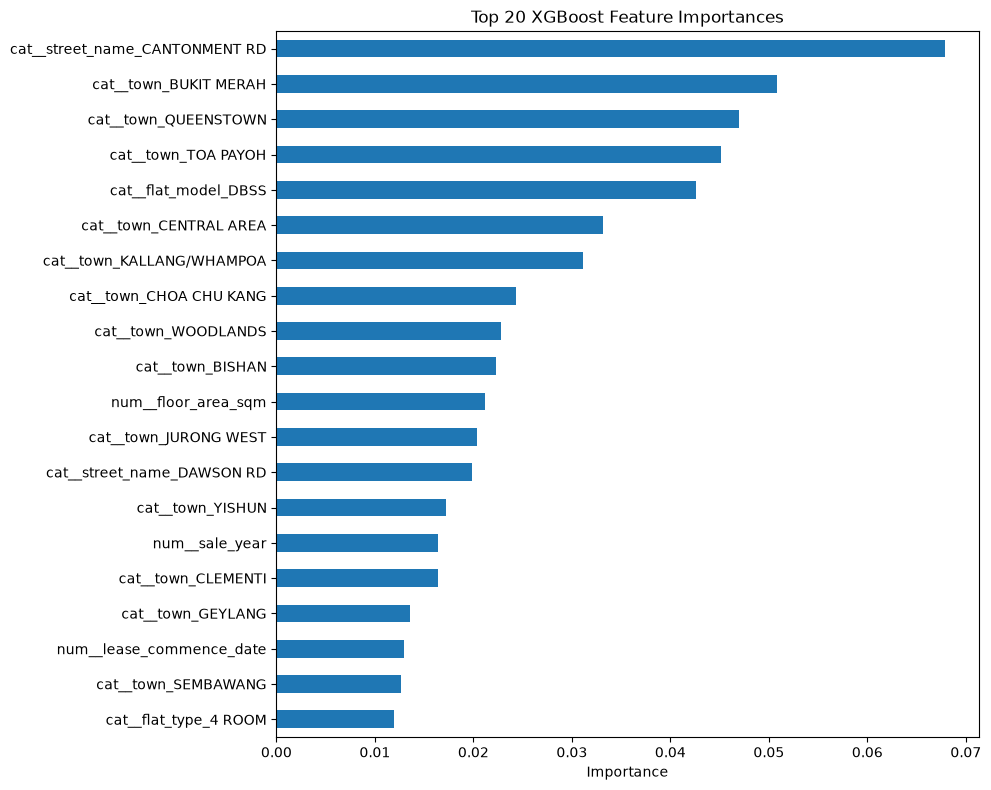

In [30]:

feature_names = preprocessor.get_feature_names_out()

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importance.head(20).sort_values().plot(
    kind="barh", figsize=(10, 8)
)
plt.title("Top 20 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()